# 05 — IEEE 802.11 WLAN channel models

**Purpose.** Use the fixed-window TGn, TGac, TGah, and TGax implementations
through the common registry and OFDM pipeline. TGn profiles A–F range from a
one-tap stress case to 150 ns RMS-delay-spread environments.

The transcribed task-group resources remain `pending_independent_review`, and a
sampled window does not promise continuity with a later `realize` call.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython import get_ipython

get_ipython().run_line_magic("matplotlib", "inline")


def find_repo_root(start: Path | None = None) -> Path:
    start = Path.cwd() if start is None else start
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "configs").is_dir():
            return candidate
    raise RuntimeError("Run this notebook from a Channel Dataset repository checkout")


def as_numpy(value):
    if isinstance(value, torch.Tensor):
        return value.detach().cpu().numpy()
    return np.asarray(value)


ROOT = find_repo_root()
SOURCE_DIRECTORY = str(ROOT / "src")
if SOURCE_DIRECTORY not in sys.path:
    sys.path.insert(0, SOURCE_DIRECTORY)

from channel_dataset.core import ExecutionContext

execution = ExecutionContext("torch", "double", "cpu")
backend = execution.array_backend
print(f"Repository: {ROOT.name} | backend={execution.backend} | precision={execution.precision}")

Repository: Channel_Dataset | backend=torch | precision=double


## 1. Inspect TGn A–F and construct the packaged Model B

In [2]:
from channel_dataset.channels.wireless import ChannelSamplingRequest
from channel_dataset.channels.wireless.ieee80211 import (
    WLANChannelSamplingRequest,
    load_ieee80211_profile,
    register_ieee80211_models,
)
from channel_dataset.config import load_config
from channel_dataset.registry import ModelRegistry

for name in "ABCDEF":
    profile = load_ieee80211_profile(name)
    print(f"Model {name}: {len(profile.taps):2d} taps, nominal RMS DS={profile.rms_delay_spread_s * 1e9:5.1f} ns")

registry = ModelRegistry()
register_ieee80211_models(registry)
tgn_envelope = load_config(ROOT / "configs/wireless/ieee80211/tgn_model_b.yaml")
tgn_model = registry.create(tgn_envelope)

Model A:  1 taps, nominal RMS DS=  0.0 ns
Model B:  9 taps, nominal RMS DS= 15.0 ns
Model C: 14 taps, nominal RMS DS= 30.0 ns
Model D: 18 taps, nominal RMS DS= 50.0 ns
Model E: 18 taps, nominal RMS DS=100.0 ns
Model F: 18 taps, nominal RMS DS=150.0 ns


## 2. Sample TGn Model B and apply it to OFDM

In [3]:
from channel_dataset.channels.wireless.operators import apply_ofdm
from channel_dataset.channels.wireless.transforms import cir_to_ofdm, subcarrier_frequencies


def tgn_request():
    sampling = ChannelSamplingRequest(1, 8, 20_000.0, execution, execution.random_stream(5501), "tgn-b")
    return WLANChannelSamplingRequest(sampling)


tgn_cir = tgn_model.realize(tgn_request())
tgn_replay = tgn_model.realize(tgn_request())
frequencies = subcarrier_frequencies(64, 312_500.0, execution)
tgn_response = cir_to_ofdm(tgn_cir, frequencies)
grid = backend.ones((1, 1, 2, 8, 64), dtype=execution.complex_dtype)
received = apply_ofdm(tgn_response, grid)

assert torch.equal(tgn_cir.coefficients, tgn_replay.coefficients)
assert tuple(received.shape) == (1, 1, 2, 8, 64)
assert torch.isfinite(received).all()
print("TGn CIR:", tgn_cir.shape, "received grid:", tuple(received.shape))
print("standard:", tgn_cir.metadata.standard_version, "seed:", tgn_cir.metadata.root_seed)

TGn CIR: (1, 1, 2, 1, 2, 9, 8) received grid: (1, 1, 2, 8, 64)
standard: 03/940r4 seed: 5501


## 3. Sample representative TGac, TGah, and TGax configurations

Large-scale WLAN modes and TGac multiuser operation require a topology. This helper
builds deterministic public `TopologyBatch` objects so the geometry is explicit.

In [4]:
from channel_dataset.channels.wireless import TopologyBatch
from channel_dataset.core import RealizationMetadata


def topology(rx_x, *, tx_z=3.0, rx_z=1.5, indoor=True):
    count = len(rx_x)
    tx_positions = backend.array([[[0.0, 0.0, tx_z]]], dtype="float64")
    rx_positions = backend.array([[[x, 0.0, rx_z] for x in rx_x]], dtype="float64")
    tx_zero = backend.zeros((1, 1, 3), dtype="float64")
    rx_zero = backend.zeros((1, count, 3), dtype="float64")
    metadata = RealizationMetadata(
        "wireless", "notebook_topology", 1, "torch", "double", "cpu",
        "deterministic", "0" * 64, {}, "0.1.0",
    )
    return TopologyBatch(
        tx_positions, rx_positions, tx_zero, rx_zero, tx_zero, rx_zero,
        backend.full((1, count), indoor, dtype="bool"),
        backend.zeros((1, 1), dtype="int64"), metadata,
        link_mask=backend.full((1, count, 1), True, dtype="bool"),
    )


cases = [
    ("TGac MU", "tgac_multiuser.yaml", topology((20.0, 35.0))),
    ("TGah indoor", "tgah_indoor.yaml", topology((15.0,))),
    ("TGax indoor", "tgax_indoor.yaml", topology((25.0,))),
]
realizations = {"TGn B": tgn_cir}
for index, (label, filename, case_topology) in enumerate(cases):
    envelope = load_config(ROOT / "configs/wireless/ieee80211" / filename)
    model = registry.create(envelope)
    sampling = ChannelSamplingRequest(1, 4, 20_000.0, execution, execution.random_stream(5510 + index), label)
    cir = model.realize(WLANChannelSamplingRequest(sampling, case_topology))
    assert torch.isfinite(cir.coefficients).all()
    realizations[label] = cir
    print(f"{label:12s}: {cir.shape}, standard={cir.metadata.standard_version}")

TGac MU     : (1, 2, 2, 1, 8, 18, 4), standard=09/0308r12


TGah indoor : (1, 1, 1, 1, 1, 9, 4), standard=11/0968r4


TGax indoor : (1, 1, 2, 1, 4, 18, 4), standard=14/0882r4


## 4. Compare power-delay profiles and within-window fading

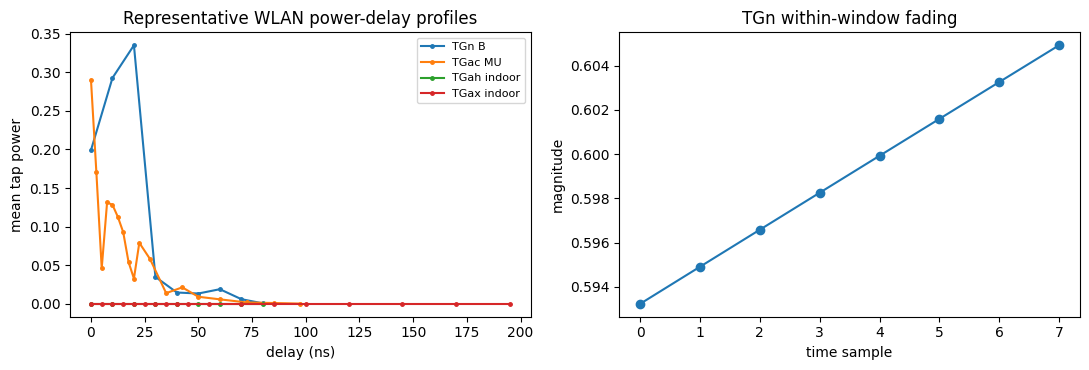

All displayed coefficients belong to one fixed requested window.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for label, realization in realizations.items():
    power = torch.mean(torch.abs(realization.coefficients[0, 0, :, 0, :, :, :]) ** 2, dim=(0, 1, 3))
    delays = realization.delays_s[0, 0, 0]
    axes[0].plot(as_numpy(delays) * 1e9, as_numpy(power), marker="o", markersize=2.5, label=label)
axes[0].set(title="Representative WLAN power-delay profiles", xlabel="delay (ns)", ylabel="mean tap power")
axes[0].legend(fontsize=8)
coefficient = tgn_cir.coefficients[0, 0, 0, 0, 0, 0]
axes[1].plot(as_numpy(torch.abs(coefficient)), marker="o")
axes[1].set(title="TGn within-window fading", xlabel="time sample", ylabel="magnitude")
fig.tight_layout()
plt.show()
print("All displayed coefficients belong to one fixed requested window.")

## Manual check and next experiments

- Compare TGn A–F delay spreads and spatial covariance.
- Reorder TGac users while preserving their coordinates; user streams should follow identity.
- Exercise TGah station-to-station and TGax outdoor UMi packaged configurations.
- Enable one environmental effect at a time and confirm other labeled random streams stay stable.